1. Mengimpor Library dan Dataset

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Mengambil dataset
transfusion=pd.read_csv("transfusion.data")

#Memisahkan fitur dan target
X=transfusion.iloc[:, :-1]
y=transfusion.iloc[:, -1].rename("Donor")

#Menggabungkan fitur dan target
df=X.copy()
df["Donor"] = y

#Menampilkan lima baris pertama
print(df.head())

   Recency (months)  Frequency (times)  Monetary (c.c. blood)  Time (months)  \
0                 2                 50                  12500             98   
1                 0                 13                   3250             28   
2                 1                 16                   4000             35   
3                 2                 20                   5000             45   
4                 1                 24                   6000             77   

   Donor  
0      1  
1      1  
2      1  
3      1  
4      0  


2. Eksplorasi Data

In [13]:
#Dimensi dataset
print("Dimensi dataset:", df.shape)

#Informasi variabel
print(df.info())

#Statistik deskriptif
print(df.describe())

#Memeriksa missing values
print(df.isnull().sum())

#Memeriksa duplikasi
print("Jumlah duplikasi:", df.duplicated().sum())

#Distribusi kelas
print(df["Donor"].value_counts())

#Persentase distribusi kelas
print(df["Donor"].value_counts(normalize=True)*100)

Dimensi dataset: (748, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Recency (months)       748 non-null    int64
 1   Frequency (times)      748 non-null    int64
 2   Monetary (c.c. blood)  748 non-null    int64
 3   Time (months)          748 non-null    int64
 4   Donor                  748 non-null    int64
dtypes: int64(5)
memory usage: 29.3 KB
None
       Recency (months)  Frequency (times)  Monetary (c.c. blood)  \
count        748.000000         748.000000             748.000000   
mean           9.506684           5.514706            1378.676471   
std            8.095396           5.839307            1459.826781   
min            0.000000           1.000000             250.000000   
25%            2.750000           2.000000             500.000000   
50%            7.000000           4.000000            1000.000

3. Visualisasi Distribusi Kelas

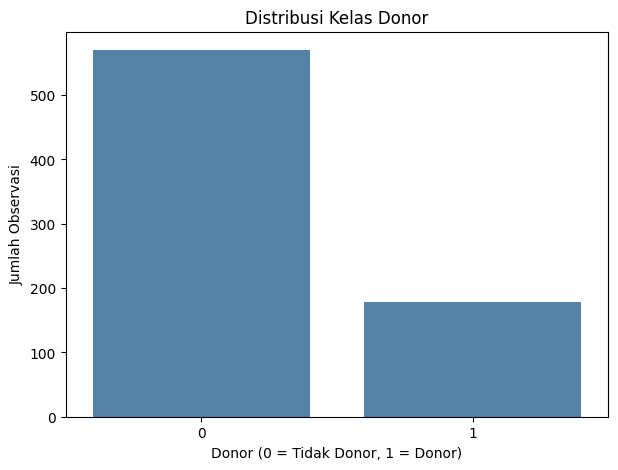

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Donor",
    order=[0, 1],
    color="steelblue"
)

plt.title("Distribusi Kelas Donor")
plt.xlabel("Donor (0 = Tidak Donor, 1 = Donor)")
plt.ylabel("Jumlah Observasi")

plt.show()

4. Membagi Data Latih dan Data Uji

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

print("\nDistribusi kelas data latih:")
print(y_train.value_counts())

print("\nDistribusi kelas data uji:")
print(y_test.value_counts())

Jumlah data latih: 598
Jumlah data uji: 150

Distribusi kelas data latih:
Donor
0    456
1    142
Name: count, dtype: int64

Distribusi kelas data uji:
Donor
0    114
1     36
Name: count, dtype: int64


5. Pemeriksaan Distribusi Kelas pada Data Training dan Data Testing

In [16]:
#Distribusi kelas pada data training
print("Distribusi Kelas Training:")
print(y_train.value_counts())

print("\nPersentase Kelas Training:")
print(y_train.value_counts(normalize=True)*100)

#Distribusi kelas pada data testing
print("\nDistribusi Kelas Testing:")
print(y_test.value_counts())

print("\nPersentase Kelas Testing:")
print(y_test.value_counts(normalize=True)*100)

Distribusi Kelas Training:
Donor
0    456
1    142
Name: count, dtype: int64

Persentase Kelas Training:
Donor
0    76.254181
1    23.745819
Name: proportion, dtype: float64

Distribusi Kelas Testing:
Donor
0    114
1     36
Name: count, dtype: int64

Persentase Kelas Testing:
Donor
0    76.0
1    24.0
Name: proportion, dtype: float64


6. Penerapan SMOTE pada Data Training

In [17]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

#Standardisasi berdasarkan data training
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

#Menerapkan SMOTE
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Sebelum SMOTE:")
print(y_train.value_counts())

print("\nSetelah SMOTE:")
print(y_train_smote.value_counts())

Sebelum SMOTE:
Donor
0    456
1    142
Name: count, dtype: int64

Setelah SMOTE:
Donor
1    456
0    456
Name: count, dtype: int64


7. Membangun Model Klasifikasi

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

models = {
    "DT - Asli": Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "DT - SMOTE": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "RF - Asli": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "RF - SMOTE": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ])
}

#Melatih keempat model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} berhasil dilatih")

DT - Asli berhasil dilatih
DT - SMOTE berhasil dilatih
RF - Asli berhasil dilatih
RF - SMOTE berhasil dilatih


8. Melakukan Prediksi pada Data Training dan Data Testing

In [19]:
predictions = {}

for name, model in models.items():

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    predictions[name] = {
        "Training": y_pred_train,
        "Testing": y_pred_test
    }

    print(f"\n{name}")
    print("Prediksi Training:", y_pred_train[:5])
    print("Prediksi Testing :", y_pred_test[:5])


DT - Asli
Prediksi Training: [1 0 0 0 0]
Prediksi Testing : [1 0 0 0 0]

DT - SMOTE
Prediksi Training: [1 0 0 0 0]
Prediksi Testing : [1 0 0 1 1]

RF - Asli
Prediksi Training: [1 0 0 0 0]
Prediksi Testing : [1 0 0 0 0]

RF - SMOTE
Prediksi Training: [1 0 0 0 0]
Prediksi Testing : [1 0 0 1 0]


9. Mengevaluasi kinerja model klasifikasi

In [20]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

evaluation_results = []

for name in models.keys():

    for dataset, y_actual in [
        ("Training", y_train),
        ("Testing", y_test)
    ]:

        y_pred = predictions[name][dataset]

        evaluation_results.append({
            "Model": name,
            "Dataset": dataset,
            "Accuracy": accuracy_score(y_actual, y_pred),
            "Precision": precision_score(
                y_actual, y_pred,
                pos_label=1,
                zero_division=0
            ),
            "Recall": recall_score(
                y_actual, y_pred,
                pos_label=1,
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_actual, y_pred,
                pos_label=1,
                zero_division=0
            )
        })

evaluation_df = pd.DataFrame(evaluation_results)

print(evaluation_df.round(4).to_string(index=False))

     Model  Dataset  Accuracy  Precision  Recall  F1-Score
 DT - Asli Training    0.9381     1.0000  0.7394    0.8502
 DT - Asli  Testing    0.7133     0.3871  0.3333    0.3582
DT - SMOTE Training    0.9130     0.8214  0.8099    0.8156
DT - SMOTE  Testing    0.6667     0.3333  0.3889    0.3590
 RF - Asli Training    0.9381     0.9730  0.7606    0.8538
 RF - Asli  Testing    0.7467     0.4667  0.3889    0.4242
RF - SMOTE Training    0.9097     0.7750  0.8732    0.8212
RF - SMOTE  Testing    0.6933     0.3913  0.5000    0.4390


10. Memvisualisasikan Confusion Matrix

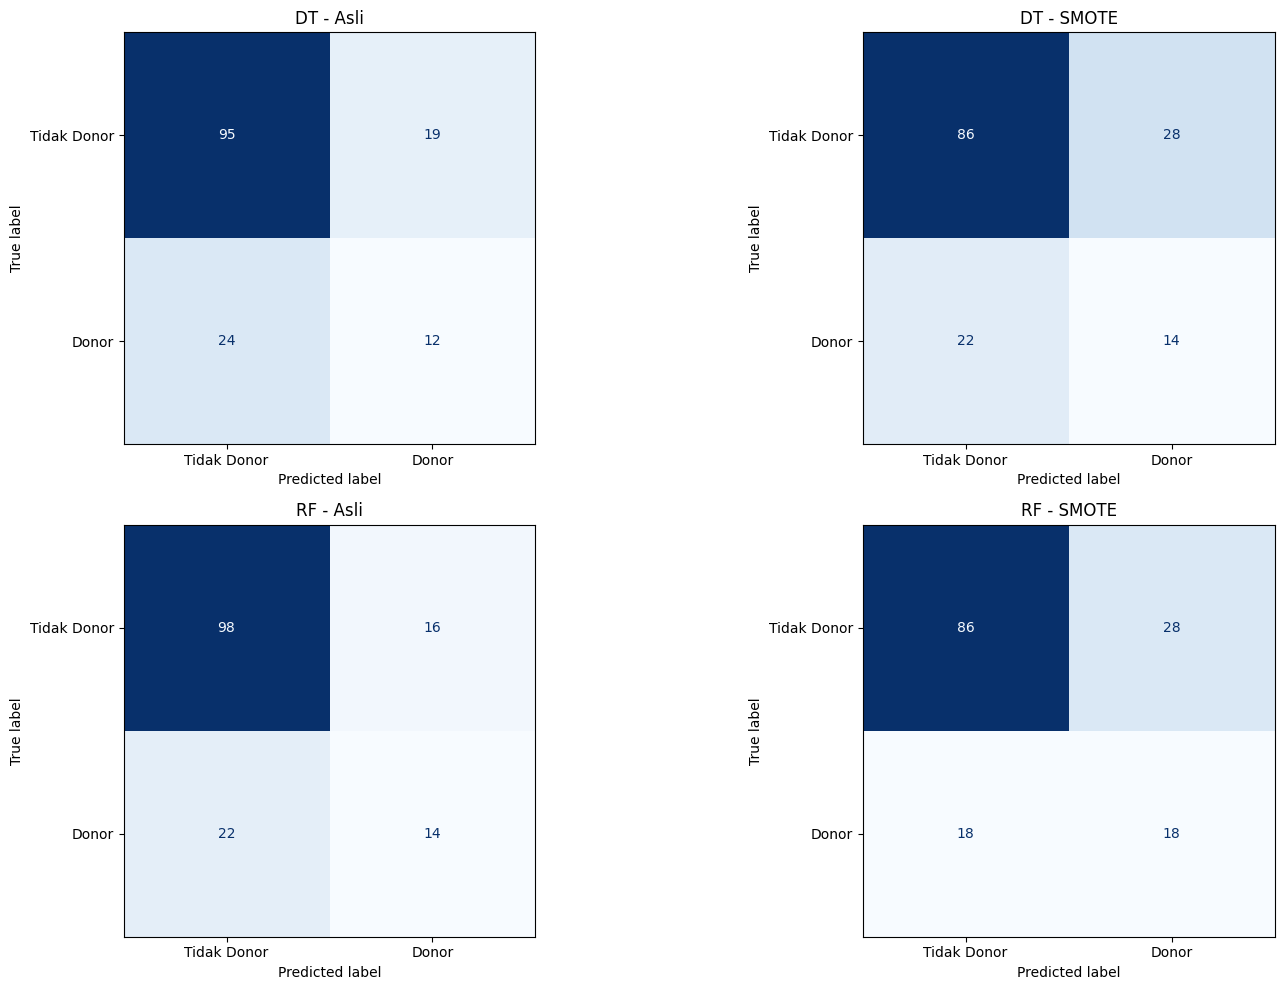

In [21]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (name, model) in zip(axes.flat, models.items()):

    y_pred = predictions[name]["Testing"]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Tidak Donor", "Donor"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

11. Membandingkan kinerja keempat model

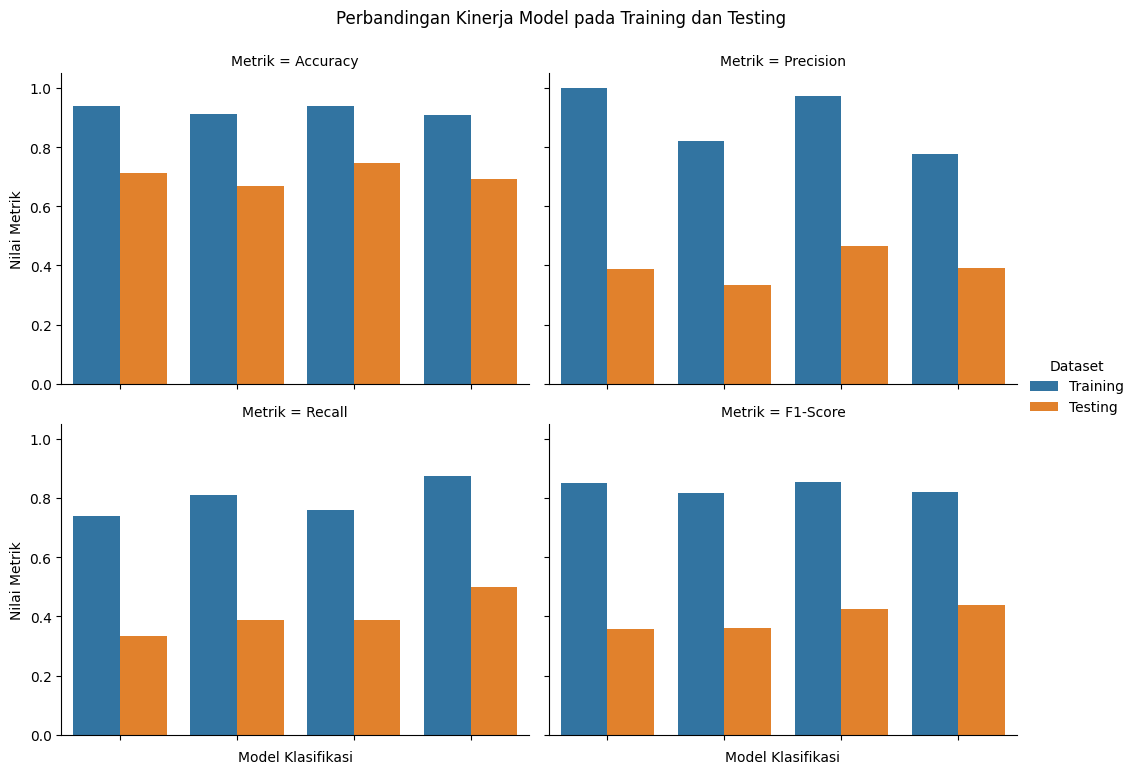

Peringkat Model Berdasarkan F1-Score Testing
     Model Dataset  Accuracy  Precision  Recall  F1-Score
RF - SMOTE Testing    0.6933     0.3913  0.5000    0.4390
 RF - Asli Testing    0.7467     0.4667  0.3889    0.4242
DT - SMOTE Testing    0.6667     0.3333  0.3889    0.3590
 DT - Asli Testing    0.7133     0.3871  0.3333    0.3582


In [22]:
import seaborn as sns

#Mengubah data menjadi format long
evaluation_long = evaluation_df.melt(
    id_vars=["Model", "Dataset"],
    value_vars=[
        "Accuracy", "Precision",
        "Recall", "F1-Score"
    ],
    var_name="Metrik",
    value_name="Nilai"
)

#Visualisasi seluruh metrik
g = sns.catplot(
    data=evaluation_long,
    x="Model",
    y="Nilai",
    hue="Dataset",
    col="Metrik",
    kind="bar",
    col_wrap=2,
    height=4,
    aspect=1.3,
    sharey=True
)

g.set(ylim=(0, 1.05))
g.set_xticklabels(rotation=45)
g.set_axis_labels("Model Klasifikasi", "Nilai Metrik")
g.fig.subplots_adjust(top=0.90)
g.fig.suptitle(
    "Perbandingan Kinerja Model pada Training dan Testing"
)

plt.show()

#Mengurutkan hasil evaluasi data testing
testing_results = evaluation_df[
    evaluation_df["Dataset"] == "Testing"
].copy()

testing_results = testing_results.sort_values(
    by="F1-Score",
    ascending=False
)

print("Peringkat Model Berdasarkan F1-Score Testing")
print(testing_results.round(4).to_string(index=False))

In [23]:
import numpy as np

pred_asli = models["RF - Asli"].predict(X_test)
pred_smote = models["RF - SMOTE"].predict(X_test)

print("Jumlah prediksi berbeda:",
      np.sum(pred_asli != pred_smote))

Jumlah prediksi berbeda: 18


In [24]:
import pandas as pd
import numpy as np

prob_asli = models["RF - Asli"].predict_proba(X_test)[:, 1]
prob_smote = models["RF - SMOTE"].predict_proba(X_test)[:, 1]

perbandingan = pd.DataFrame({
    "Aktual": y_test.to_numpy(),
    "Prediksi_Asli": models["RF - Asli"].predict(X_test),
    "Prediksi_SMOTE": models["RF - SMOTE"].predict(X_test),
    "Prob_Donor_Asli": prob_asli,
    "Prob_Donor_SMOTE": prob_smote
})

print(perbandingan.head(10))

   Aktual  Prediksi_Asli  Prediksi_SMOTE  Prob_Donor_Asli  Prob_Donor_SMOTE
0       1              1               1         0.720000          0.840000
1       0              0               0         0.000000          0.000000
2       0              0               0         0.000000          0.000000
3       0              0               1         0.412514          0.546283
4       0              0               0         0.291667          0.395000
5       0              1               1         0.919667          0.924474
6       0              1               1         0.610000          0.680000
7       1              0               0         0.350000          0.370000
8       1              0               0         0.126109          0.065805
9       0              0               0         0.037538          0.083774


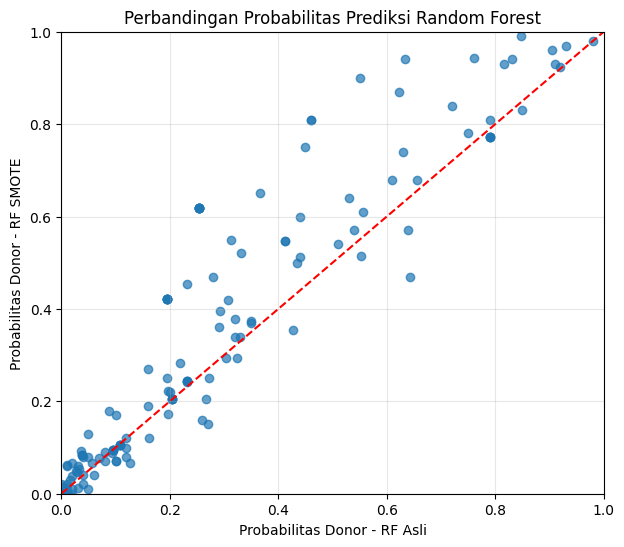

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    prob_asli,
    prob_smote,
    alpha=0.7
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("Probabilitas Donor - RF Asli")
plt.ylabel("Probabilitas Donor - RF SMOTE")
plt.title("Perbandingan Probabilitas Prediksi Random Forest")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.show()

KORELASI ANTARVARIABEL DENGAN TARGET

In [27]:
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

# a) Kolom identitas / kebocoran: tidak ada kolom ID, dan tidak ada fitur yang merupakan turunan langsung dari target.
print("Kolom kandidat fitur:", X.columns.tolist())
print("Target ikut sebagai fitur?", "Donor" in X.columns)

# b) Korelasi tiap fitur terhadap target (data latih saja)
corr_target = X_train.assign(y=y_train).corr()["y"].drop("y").sort_values(key=abs, ascending=False)
display(corr_target.round(3).to_frame("Korelasi dengan target"))

# c) VIF (cek multikolinearitas), dihitung dari data latih
def vif_table(frame):
    out = {}
    for c in frame.columns:
        r2 = LinearRegression().fit(frame.drop(columns=c), frame[c]).score(frame.drop(columns=c), frame[c])
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out, name="VIF").sort_values(ascending=False)
display(vif_table(X_train).round(2).to_frame())

Kolom kandidat fitur: ['Recency (months)', 'Frequency (times)', 'Monetary (c.c. blood)', 'Time (months)']
Target ikut sebagai fitur? False


,Korelasi dengan target
Recency (months),-0.262
Frequency (times),0.206
Monetary (c.c. blood),0.206
Time (months),-0.047


,VIF
Frequency (times),inf
Monetary (c.c. blood),inf
Time (months),1.91
Recency (months),1.19
